# Exploratory Data Analysis

In [1]:
import sys
from datetime import datetime
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import seaborn as sns

from src.data_loader import (
    download_dataset,
    load_orders,
    load_interactions,
    load_items,
    load_categories,
)

plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

## Вспомогательные функции

In [3]:
def null_count_total(lf: pl.LazyFrame | pl.DataFrame) -> int:
    if isinstance(lf, pl.DataFrame):
        return int(
            lf.select(pl.all().null_count())
            .select(pl.sum_horizontal(pl.all()).alias("total_nulls"))
            .item()
        )

    return int(
        lf.select(pl.all().null_count())
        .select(pl.sum_horizontal(pl.all()).alias("total_nulls"))
        .collect(engine="streaming")
        .item()
    )

In [4]:
def duplicate_rows_count(lf: pl.LazyFrame | pl.DataFrame) -> int:
    if isinstance(lf, pl.DataFrame):
        lf = lf.lazy()

    cols = lf.collect_schema().names()
    duplicates = (
        lf.group_by(cols)
        .len()
        .filter(pl.col("len") > 1)
        .select((pl.col("len") - 1).sum().alias("duplicates"))
        .collect(engine="streaming")
        .item()
    )
    return int(duplicates or 0)

In [5]:
def parse_date(column: str) -> pl.Expr:
    as_str = pl.col(column).cast(pl.Utf8)
    return pl.coalesce(
        [
            as_str.str.strptime(pl.Date, strict=False),
            as_str.str.strptime(pl.Datetime, strict=False).dt.date(),
        ]
    )

In [6]:
def value_counts_col(lf: pl.LazyFrame | pl.DataFrame, column: str) -> pd.DataFrame:
    if isinstance(lf, pl.DataFrame):
        lf = lf.lazy()

    counts = (
        lf.group_by(column)
        .len()
        .sort("len", descending=True)
        .collect(engine="streaming")
        .rename({"len": "count"})
        .to_pandas()
    )
    counts["percentage"] = counts["count"].apply(
        lambda x: f"{x / counts['count'].sum():.2%}"
    )
    return counts

In [7]:
def plot_orders_per_day(lf: pl.LazyFrame | pl.DataFrame):
    if isinstance(lf, pl.DataFrame):
        lf = lf.lazy()

    daily_orders = (
        lf.with_columns(parse_date("created_date").alias("created_date"))
        .group_by("created_date")
        .len()
        .sort("created_date")
        .collect(engine="streaming")
    )

    sns.set_theme(style="whitegrid", font_scale=1.2, palette="muted")
    plt.figure(figsize=(10, 5))
    sns.lineplot(
        x=daily_orders["created_date"].to_list(),
        y=daily_orders["len"].to_list(),
        color="#4C72B0",
    )
    plt.title("Количество заказов по дням", fontsize=16, weight="bold")
    plt.xlabel("Дата")
    plt.ylabel("Количество заказов")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [8]:
def plot_orders_status(lf: pl.LazyFrame | pl.DataFrame):

    status_counts_df = value_counts_col(lf, "last_status")

    sns.set_theme(style="whitegrid", font_scale=1.2, palette="muted")
    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=status_counts_df,
        x="last_status",
        y="count",
        color="#55A868",
        width=0.4,
    )

    plt.title("Распределение статусов заказов", fontsize=16, weight="bold")
    plt.xlabel("Статус")
    plt.ylabel("Количество заказов")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [9]:
def plot_distribution(
    lf: pl.LazyFrame | pl.DataFrame,
    limit_cnt: int = 1_000_000_000,
    log_scale: bool = False,
    data_title: str = "",
):
    if isinstance(lf, pl.DataFrame):
        lf = lf.lazy()

    log_scale_value = (True, False) if log_scale else None
    log_title = " (логарифмическая шкала)" if log_scale else ""

    data = lf.group_by("user_id").len().collect(engine="streaming")["len"].to_pandas()

    sns.set_theme(style="whitegrid", font_scale=1.2)
    plt.figure(figsize=(10, 6))

    sns.histplot(
        data[data < limit_cnt],
        bins=50,
        color="#4C72B0",
        alpha=0.75,
        log_scale=log_scale_value,
    )

    mean_val = data.mean()
    median_val = data.median()
    plt.axvline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Среднее: {mean_val:.1f}",
    )
    plt.axvline(
        median_val,
        color="green",
        linestyle="-.",
        linewidth=2,
        label=f"Медиана: {median_val:.1f}",
    )

    plt.title(
        f"Распределение количества {data_title} на пользователя{log_title}",
        fontsize=16,
        weight="bold",
        pad=15,
    )
    plt.xlabel(f"Количество {data_title}", fontsize=13)
    plt.ylabel("Число пользователей", fontsize=13)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [10]:
def plot_action_per_hours_week_days(
    lf: pl.LazyFrame | pl.DataFrame,
    timestamp_col: str,
    title: str,
):
    if isinstance(lf, pl.DataFrame):
        lf = lf.lazy()

    agg = (
        lf.filter(pl.col(timestamp_col).is_not_null())
        .select(
            weekday_num=pl.col(timestamp_col).dt.weekday(),
            hour=pl.col(timestamp_col).dt.hour(),
        )
        .group_by(["weekday_num", "hour"])
        .len()
        .collect(engine="streaming")
    )

    day_names = {
        1: "Понедельник",
        2: "Вторник",
        3: "Среда",
        4: "Четверг",
        5: "Пятница",
        6: "Суббота",
        7: "Воскресенье",
    }

    heatmap_df = (
        agg.to_pandas()
        .assign(dayofweek=lambda df: df["weekday_num"].map(day_names))
        .pivot(index="dayofweek", columns="hour", values="len")
        .reindex(
            ["Понедельник", "Вторник", "Среда", "Четверг", "Пятница", "Суббота", "Воскресенье"]
        )
        .fillna(0)
    )

    plt.figure(figsize=(12, 4))
    sns.set_theme(style="whitegrid", font_scale=1.1)
    ax = sns.heatmap(
        heatmap_df,
        cmap="YlGnBu",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Количество"},
    )

    ax.set_title(
        f"{title} пользователей по дням недели и времени суток",
        fontsize=16,
        weight="bold",
        pad=15,
    )
    ax.set_xlabel("Час суток", fontsize=12)
    ax.set_ylabel("День недели", fontsize=12)
    plt.tight_layout()
    plt.show()

In [11]:
def plot_action_types(lf: pl.LazyFrame | pl.DataFrame):
    action_counts_df = value_counts_col(lf, "action_type")

    plt.figure(figsize=(8, 5))
    sns.barplot(data=action_counts_df, x="action_type", y="count", color="#C44E52")
    plt.title("Распределение типов действий", fontsize=16, weight="bold")
    plt.xlabel("Тип действия")
    plt.ylabel("Количество действий")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Загрузка датасета

In [12]:
download_dataset()

Датасет загружен ранее


## Анализ данных

### Информация о заказах:
- ml_ozon_recsys_train_final_apparel_orders_data
- archive_extra_orders_data/archive_extra_orders_data

#### Информация о заказах с 1 января по 1 июля:
- ml_ozon_recsys_train_final_apparel_orders_data

In [13]:
# В каталоге ml_ozon_recsys_train_final_apparel_orders_data 5 parquet файлов
orders_dir = DATA_DIR / "ml_ozon_recsys_train_final_apparel_orders_data"
sorted(p.name for p in orders_dir.iterdir())

['_SUCCESS',
 'part-00000-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00001-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00002-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00003-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00004-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet']

In [14]:
orders_lf = load_orders(train=True)
orders_lf.head().collect()

item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
i32,i32,datetime[ns],str,datetime[ns],str
15535,3423970,2025-01-11 19:20:02.550,"""delivered_orders""",2025-01-16 10:53:03,"""2025-01-11"""
15535,1207601,2025-03-25 13:11:48.240,"""canceled_orders""",2025-03-29 08:32:43,"""2025-03-25"""
119241,2340021,2025-05-03 20:46:18.146,"""canceled_orders""",2025-05-12 17:10:27,"""2025-05-03"""
119241,2356390,2025-05-01 17:53:00.716,"""delivered_orders""",2025-05-14 14:36:20,"""2025-05-01"""
119241,1490080,2025-04-22 22:59:11.160,"""canceled_orders""",2025-04-26 06:27:28,"""2025-04-22"""


In [15]:
print("АНАЛИЗ ЗАКАЗОВ")
print("=" * 50)

orders_summary = (
    orders_lf.select(
        total_orders=pl.len(),
        unique_users=pl.col("user_id").n_unique(),
        unique_items=pl.col("item_id").n_unique(),
        min_date=pl.col("created_date").min(),
        max_date=pl.col("created_date").max(),
    )
    .collect()
    .row(0, named=True)
)

print("Общее количество заказов: {:,}".format(orders_summary["total_orders"]))
print("Уникальных пользователей: {:,}".format(orders_summary["unique_users"]))
print("Уникальных товаров:       {:,}".format(orders_summary["unique_items"]))
print("Период данных:            {} - {}".format(
    orders_summary["min_date"],
    orders_summary["max_date"],
    )
)
print("Количество пропусков:     {:,}".format(null_count_total(orders_lf)))
print("Количество дублей:        {:,}".format(duplicate_rows_count(orders_lf)))

АНАЛИЗ ЗАКАЗОВ
Общее количество заказов: 18,887,122
Уникальных пользователей: 834,137
Уникальных товаров:       4,673,763
Период данных:            2025-01-01 - 2025-07-01
Количество пропусков:     0
Количество дублей:        201,219


In [16]:
print("Дубли - вероятно, несколько одинаковых позиций в заказе")

duplicates = (
    orders_lf
    .filter(pl.struct(pl.all()).is_duplicated())
    .sort(["user_id", "item_id", "created_timestamp"])
    .head(10)
    .collect()
)

duplicates

Дубли - вероятно, несколько одинаковых позиций в заказе


item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
i32,i32,datetime[ns],str,datetime[ns],str
264778815,1,2025-02-17 20:08:40.530,"""delivered_orders""",2025-02-20 20:05:06,"""2025-02-17"""
264778815,1,2025-02-17 20:08:40.530,"""delivered_orders""",2025-02-20 20:05:06,"""2025-02-17"""
145229551,210,2025-01-15 13:14:51.986,"""canceled_orders""",2025-02-13 08:01:25,"""2025-01-15"""
145229551,210,2025-01-15 13:14:51.986,"""canceled_orders""",2025-02-13 08:01:25,"""2025-01-15"""
187052809,270,2025-01-18 14:46:28.656,"""delivered_orders""",2025-01-22 18:44:43,"""2025-01-18"""
187052809,270,2025-01-18 14:46:28.656,"""delivered_orders""",2025-01-22 18:44:43,"""2025-01-18"""
174922942,280,2025-05-08 23:14:15.650,"""delivered_orders""",2025-05-10 15:30:10,"""2025-05-08"""
174922942,280,2025-05-08 23:14:15.650,"""delivered_orders""",2025-05-10 15:30:10,"""2025-05-08"""
174922942,280,2025-05-09 21:08:55.173,"""delivered_orders""",2025-05-11 18:46:42,"""2025-05-09"""


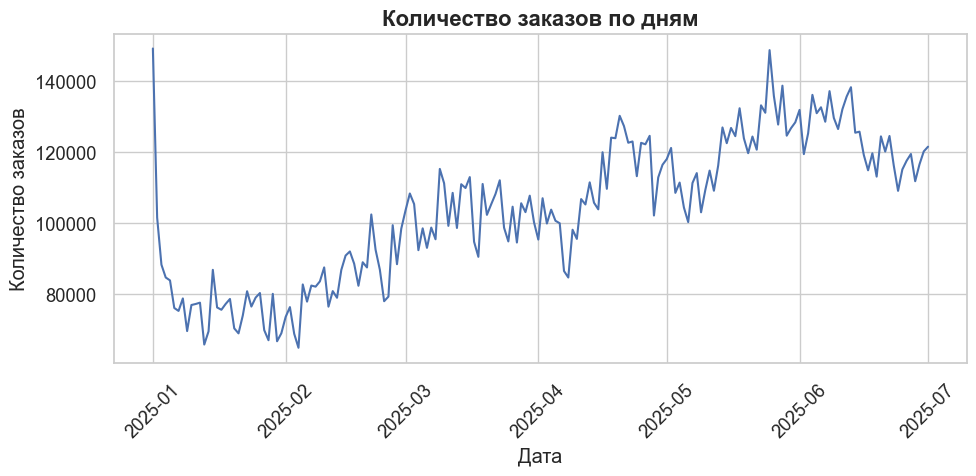

In [17]:
plot_orders_per_day(orders_lf)

Распределение статусов заказов:
                    count percentage
delivered_orders  9936249     52.61%
canceled_orders   7990577     42.31%
proccesed_orders   960296      5.08%


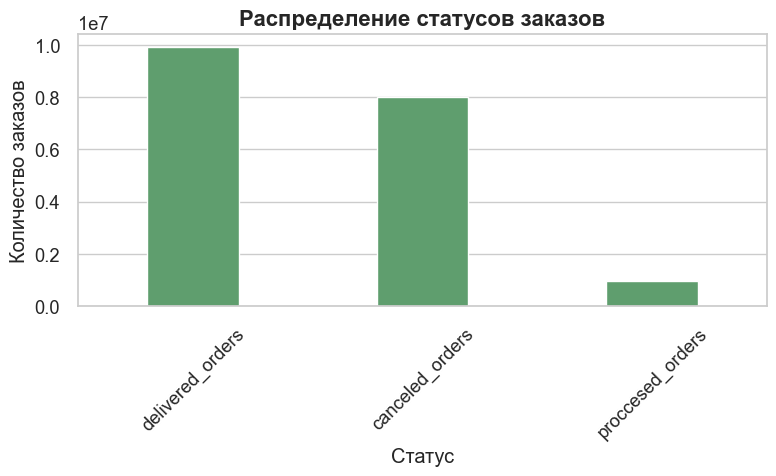

In [18]:
status_counts_df = value_counts_col(orders_lf, "last_status")
status_counts_df.set_index("last_status", inplace=True)
status_counts_df.index.name = None

print("Распределение статусов заказов:")
print(status_counts_df)

plot_orders_status(orders_lf)

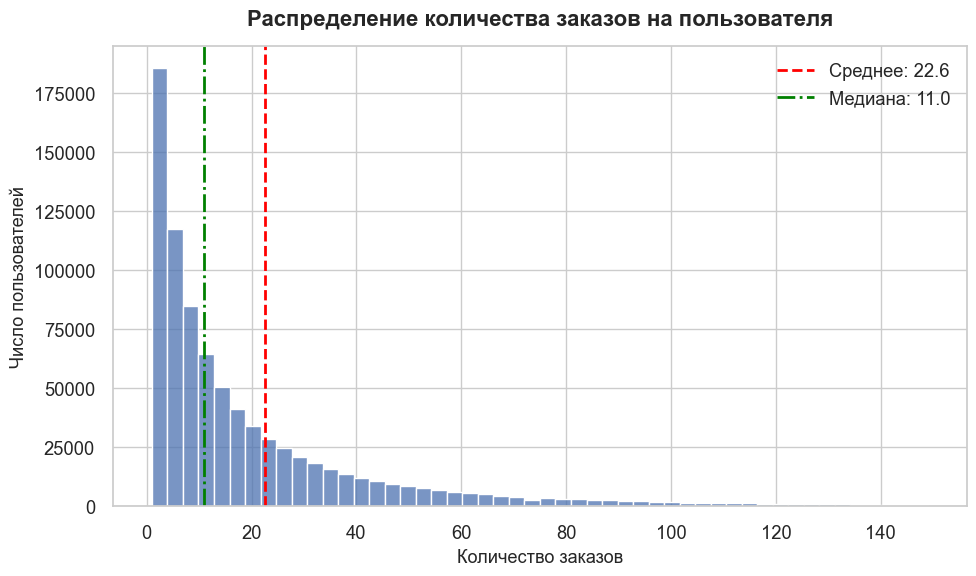

In [19]:
plot_distribution(orders_lf, 150, False, 'заказов')

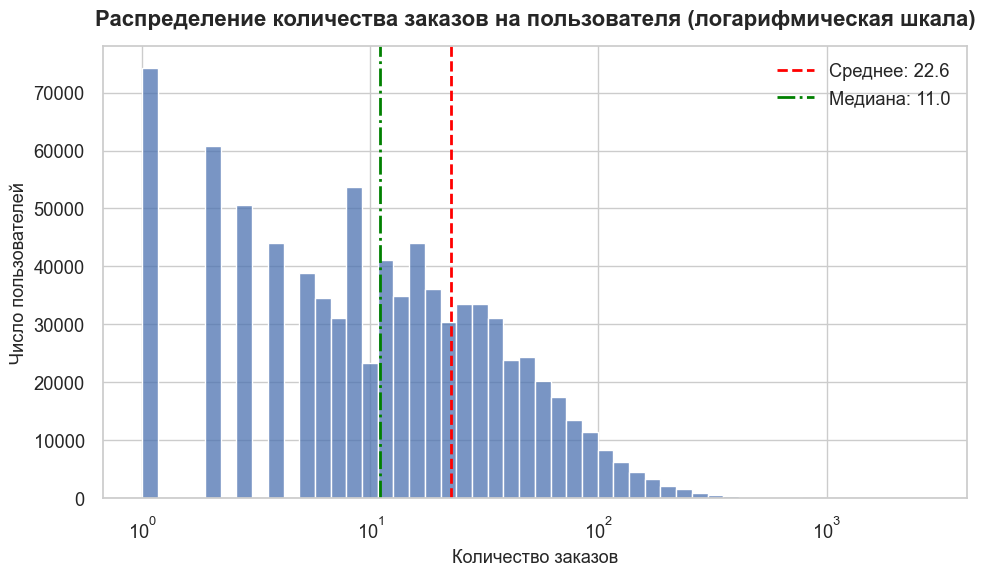

In [20]:
plot_distribution(orders_lf, 1_000_000_000, True, 'заказов')

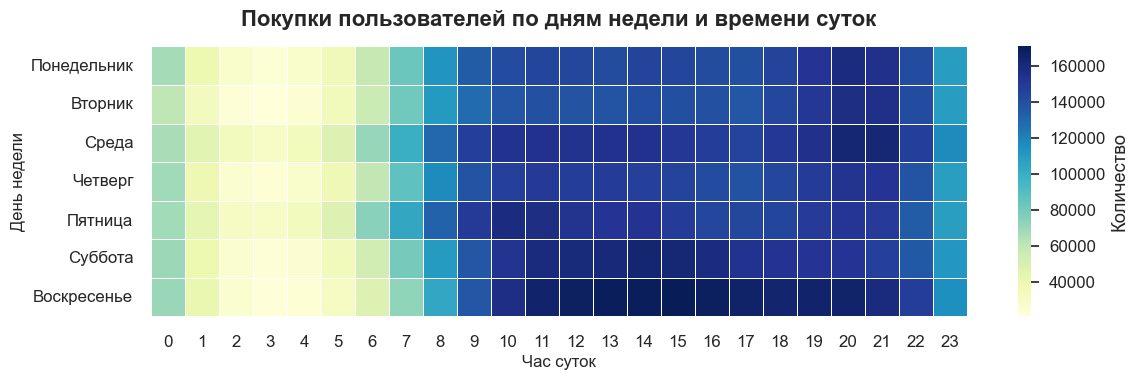

In [21]:
plot_action_per_hours_week_days(orders_lf, "created_timestamp", "Покупки")

#### Информация о заказах с 2 по 15 июля:
- archive_extra_orders_data/final_apparel_orders_data_07

In [22]:
orders_new_dir = DATA_DIR / "archive_extra_orders_data" / "final_apparel_orders_data_07"
for partition_dir in sorted(p for p in orders_new_dir.iterdir() if p.is_dir()):
    partition_value = partition_dir.name
    parquet_count = len(list(partition_dir.glob("*.parquet")))
    print(f"В партиции {partition_value} {parquet_count} parquet файла")

В партиции created_date=2025-07-02 2 parquet файла
В партиции created_date=2025-07-03 2 parquet файла
В партиции created_date=2025-07-04 2 parquet файла
В партиции created_date=2025-07-05 2 parquet файла
В партиции created_date=2025-07-06 2 parquet файла
В партиции created_date=2025-07-07 2 parquet файла
В партиции created_date=2025-07-08 2 parquet файла
В партиции created_date=2025-07-09 2 parquet файла
В партиции created_date=2025-07-10 2 parquet файла
В партиции created_date=2025-07-11 2 parquet файла
В партиции created_date=2025-07-12 2 parquet файла
В партиции created_date=2025-07-13 2 parquet файла
В партиции created_date=2025-07-14 2 parquet файла
В партиции created_date=2025-07-15 2 parquet файла


In [23]:
orders_new_lf = load_orders(train=False)
orders_new_lf.head().collect()

item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
i32,i32,datetime[ns],str,datetime[ns],date
7510328,981,2025-07-02 08:27:17.686,"""delivered_orders""",2025-07-06 16:14:12,2025-07-02
136809690,4670,2025-07-02 17:17:30.423,"""canceled_orders""",2025-07-06 19:35:07,2025-07-02
232878073,12341,2025-07-02 15:17:46.393,"""canceled_orders""",2025-07-11 15:36:40,2025-07-02
42322137,12860,2025-07-02 00:40:52.503,"""delivered_orders""",2025-07-04 19:44:48,2025-07-02
22480781,15330,2025-07-02 07:25:11.226,"""delivered_orders""",2025-07-03 20:07:33,2025-07-02


In [24]:
print("АНАЛИЗ ЗАКАЗОВ")
print("=" * 50)

orders_new_summary = (
    orders_new_lf.select(
        total_orders=pl.len(),
        unique_users=pl.col("user_id").n_unique(),
        unique_items=pl.col("item_id").n_unique(),
        min_date=pl.col("created_date").min(),
        max_date=pl.col("created_date").max(),
    )
    .collect()
    .row(0, named=True)
)

print("Общее количество заказов: {:,}".format(orders_new_summary["total_orders"]))
print("Уникальных пользователей: {:,}".format(orders_new_summary["unique_users"]))
print("Уникальных товаров:       {:,}".format(orders_new_summary["unique_items"]))
print("Период данных:            {} - {}".format(
    orders_new_summary["min_date"],
    orders_new_summary["max_date"],
    )
)
print("Количество пропусков:     {:,}".format(null_count_total(orders_new_lf)))
print("Количество дублей:        {:,}".format(duplicate_rows_count(orders_new_lf)))

АНАЛИЗ ЗАКАЗОВ
Общее количество заказов: 1,475,216
Уникальных пользователей: 346,759
Уникальных товаров:       692,335
Период данных:            2025-07-02 - 2025-07-15
Количество пропусков:     0
Количество дублей:        0


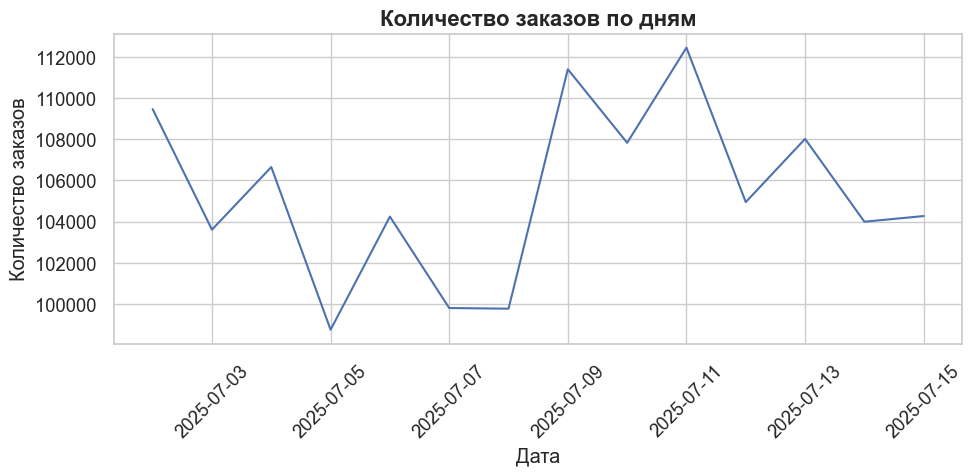

In [25]:
plot_orders_per_day(orders_new_lf)

Распределение статусов заказов:
                   count percentage
proccesed_orders  560517     38.00%
delivered_orders  484645     32.85%
canceled_orders   430054     29.15%


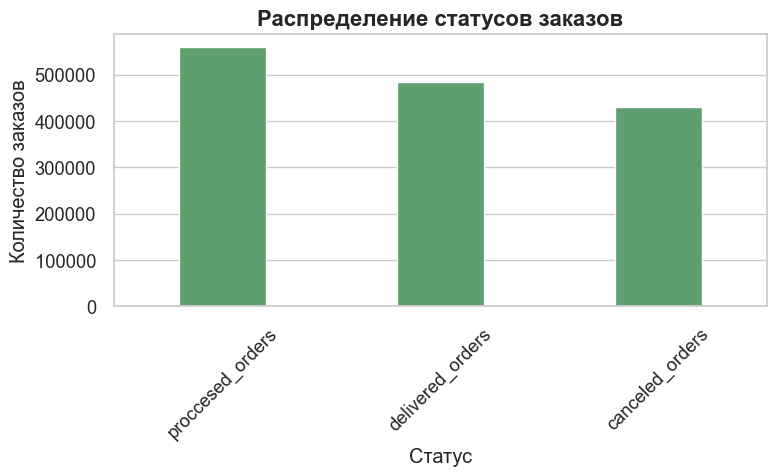

In [26]:
status_counts_new_df = value_counts_col(orders_new_lf, "last_status")
status_counts_new_df.set_index("last_status", inplace=True)
status_counts_new_df.index.name = None

print("Распределение статусов заказов:")
print(status_counts_new_df)

plot_orders_status(orders_new_lf)

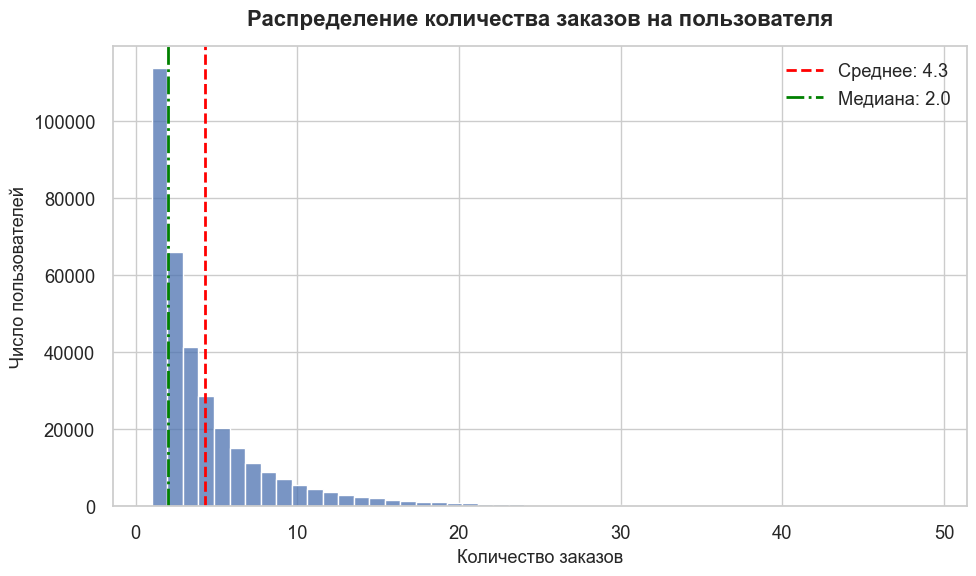

In [27]:
plot_distribution(orders_new_lf, 50, False, 'заказов')

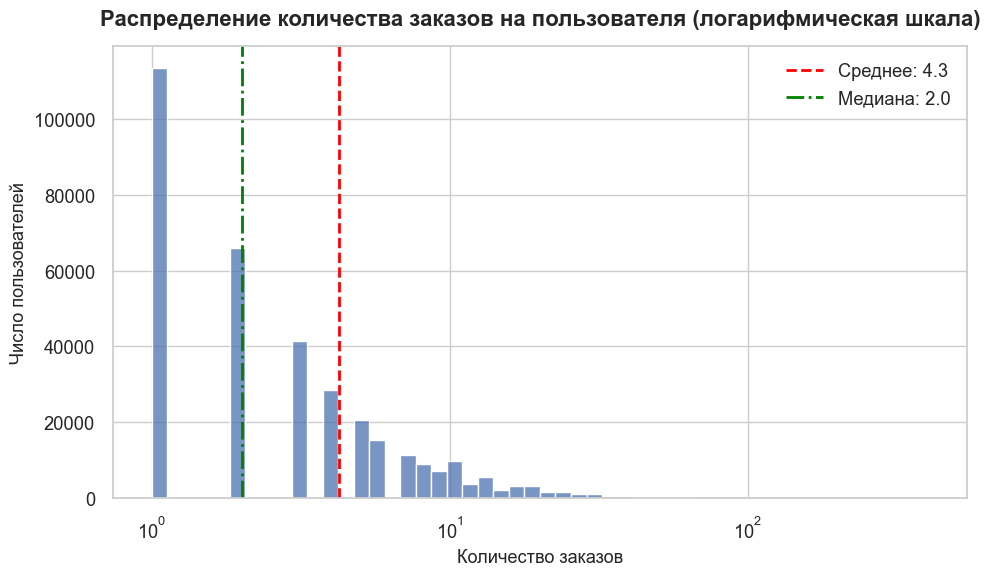

In [28]:
plot_distribution(orders_new_lf, 1_000_000_000, True, 'заказов')

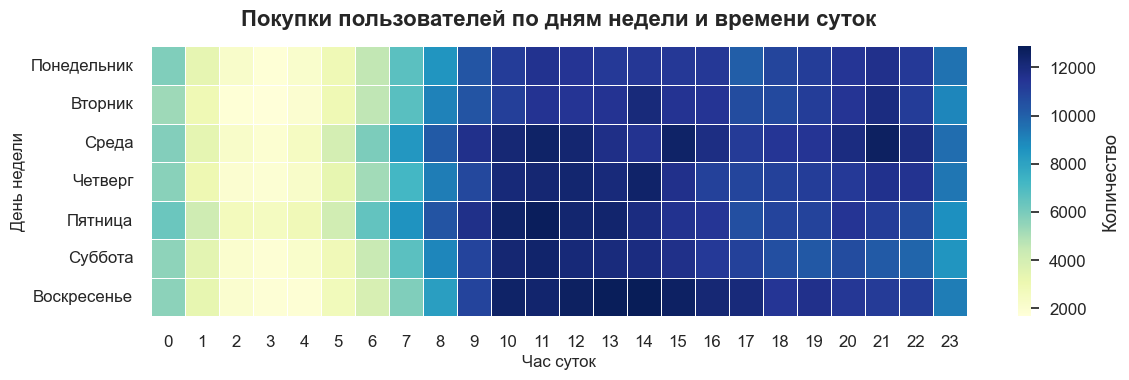

In [29]:
plot_action_per_hours_week_days(orders_new_lf, "created_timestamp", "Покупки")

### Информация о взаимодействиях:
- ml_ozon_recsys_train_final_apparel_tracker_data
- final_apparel_tracker_data_08_action_widget

#### Информация о взаимодействиях с 1 января по 1 июля:
- ml_ozon_recsys_train_final_apparel_tracker_data

In [30]:
# В каталоге ml_ozon_recsys_train_final_apparel_tracker_data 200 parquet файлов
tracker_dir = DATA_DIR / "ml_ozon_recsys_train_final_apparel_tracker_data"
tracker_files = list(p.name for p in tracker_dir.iterdir())
print(len(tracker_files))
tracker_files[-5:]

201


['part-00196-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00197-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00198-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00199-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 '_SUCCESS']

In [31]:
tracker_lf = load_interactions(train=True)
tracker_lf.head().collect()

item_id,user_id,timestamp,action_type,action_widget,date
i32,i32,datetime[ns],str,str,str
678602,4211601,2025-05-05 18:11:15,"""page_view""","""cart.cartSplit""","""2025-05-05"""
678602,4211601,2025-05-05 18:12:57,"""view_description""","""pdp.characteristics""","""2025-05-05"""
678602,4211601,2025-05-05 18:12:52,"""view_description""","""pdp.richContent""","""2025-05-05"""
678602,4211601,2025-05-05 10:39:08,"""page_view""","""cart.cartSplit""","""2025-05-05"""
678602,4211601,2025-05-05 18:12:57,"""view_description""","""pdp.characteristics""","""2025-05-05"""


In [32]:
print("АНАЛИЗ ВЗАИМОДЕЙСТВИЙ")
print("=" * 56)

tracker_summary = (
    tracker_lf.select(
        total_events=pl.len(),
        unique_users=pl.col("user_id").n_unique(),
        unique_items=pl.col("item_id").n_unique(),
        min_date=pl.col("date").min(),
        max_date=pl.col("date").max(),
    )
    .collect(engine="streaming")
    .row(0, named=True)
)

print("Общее количество взаимодействий: {:,}".format(tracker_summary["total_events"]))
print("Уникальных пользователей:        {:,}".format(tracker_summary["unique_users"]))
print("Уникальных товаров:              {:,}".format(tracker_summary["unique_items"]))
print("Период данных:                   {} - {}".format(
    tracker_summary["min_date"],
    tracker_summary["max_date"],
    )
)
print("Количество пропусков:            {:,}".format(null_count_total(tracker_lf)))

АНАЛИЗ ВЗАИМОДЕЙСТВИЙ
Общее количество взаимодействий: 1,644,982,482
Уникальных пользователей:        1,011,099
Уникальных товаров:              4,895,557
Период данных:                   2025-01-01 - 2025-07-01
Количество пропусков:            57,565,950


Распределение типов взаимодействий:
                       count percentage
page_view         1176606537     71.53%
view_description   221879384     13.49%
review_view         76459985      4.65%
to_cart             61059905      3.71%
favorite            51948578      3.16%
remove              37207155      2.26%
unfavorite          19820938      1.20%


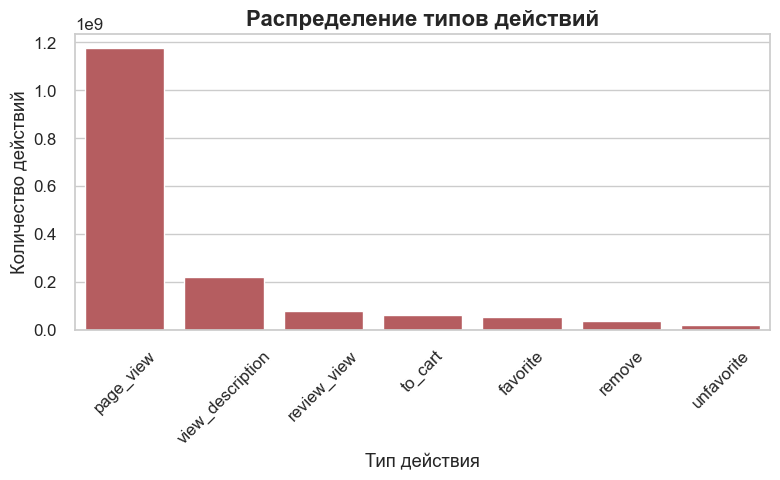

In [33]:
action_counts_df = value_counts_col(tracker_lf, "action_type")
action_counts_df.set_index("action_type", inplace=True)
action_counts_df.index.name = None

print("Распределение типов взаимодействий:")
print(action_counts_df)

plot_action_types(tracker_lf)

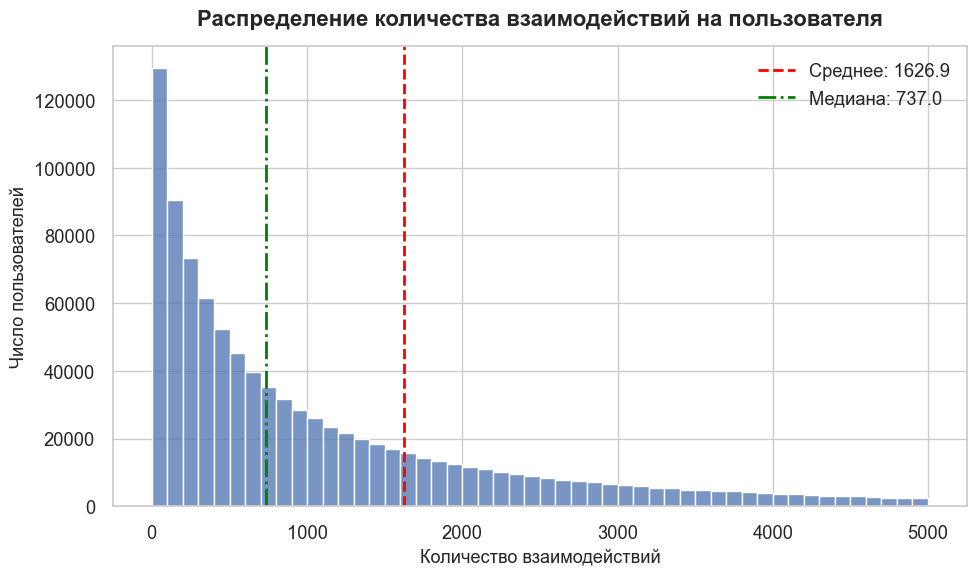

In [34]:
plot_distribution(tracker_lf, 5000, False, 'взаимодействий')

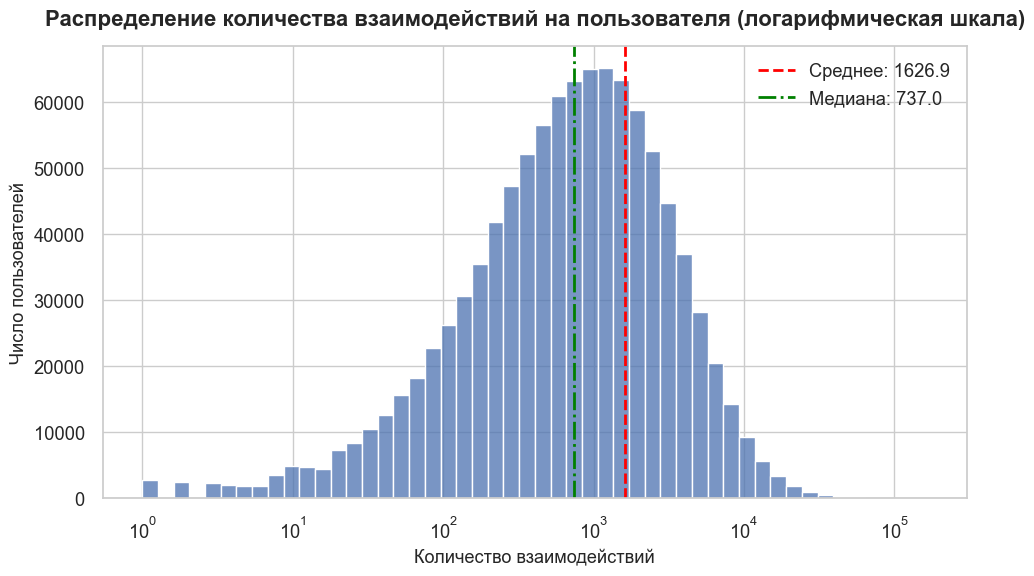

In [35]:
plot_distribution(tracker_lf, 1_000_000_000, True, 'взаимодействий')

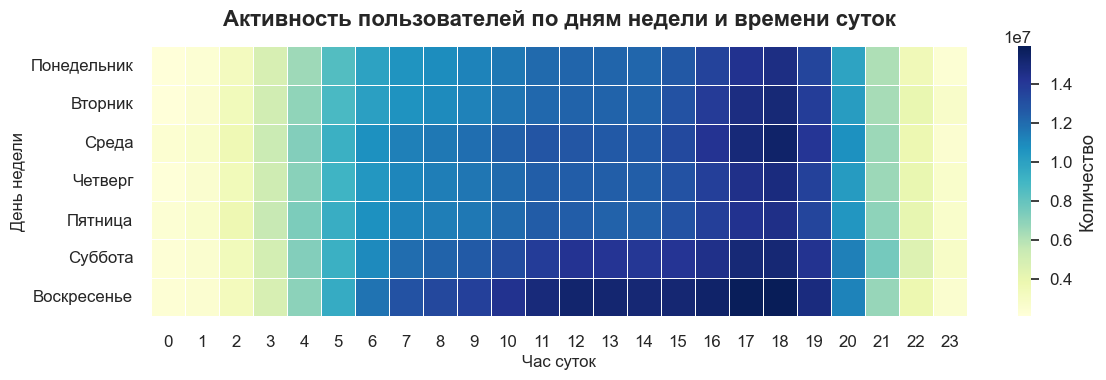

In [36]:
plot_action_per_hours_week_days(tracker_lf, "timestamp", "Активность")

In [37]:
print(
    "Количество некорректных timestamp из прошлого: {}".format(
        tracker_lf
        .filter(pl.col("timestamp") <= datetime(2024, 12, 31))
        .select(pl.len())
        .collect(engine="streaming")
        .item()
    )
)

(
    tracker_lf
    .filter(pl.col("timestamp") <= datetime(2023, 12, 31))
    .head(3)
    .collect(engine="streaming")
)

Количество некорректных timestamp из прошлого: 3783


item_id,user_id,timestamp,action_type,action_widget,date
i32,i32,datetime[ns],str,str,str
275406581,4625880,2019-04-28 07:04:24,"""view_description""","""pdp.webCharacteristics""","""2025-04-28"""
275406581,4625880,2019-04-28 07:04:24,"""page_view""","""shelf.buyTogether""","""2025-04-28"""
203708971,3534281,2022-02-20 02:14:05,"""view_description""","""pdp.webCharacteristics""","""2025-06-28"""


In [38]:
print(
    "Количество некорректных timestamp из будущего: {}".format(
        tracker_lf
        .filter(pl.col("timestamp") >= datetime(2025, 7, 2))
        .select(pl.len())
        .collect(engine="streaming")
        .item()
    )
)

(
    tracker_lf
    .filter(pl.col("timestamp") >= datetime(2026, 1, 1))
    .head(3)
    .collect(engine="streaming")
)

Количество некорректных timestamp из будущего: 2363


item_id,user_id,timestamp,action_type,action_widget,date
i32,i32,datetime[ns],str,str,str
220466124,834400,2027-02-04 00:57:00,"""page_view""","""shelf.analogShelf""","""2025-06-23"""
220466124,834400,2027-02-04 00:57:03,"""view_description""","""pdp.webCharacteristics""","""2025-06-23"""
220466124,834400,2027-02-04 00:57:01,"""view_description""","""pdp.webCharacteristics""","""2025-06-23"""


#### Информация о взаимодействиях с 2 по 15 июля:
- final_apparel_tracker_data_08_action_widget

In [39]:
tracker_new_dir = DATA_DIR / "final_apparel_tracker_data_08_action_widget"
for partition_dir in sorted(p for p in tracker_new_dir.iterdir() if p.is_dir()):
    partition_value = partition_dir.name
    parquet_count = len(list(partition_dir.glob("*.parquet")))
    print(f"В партиции {partition_value} {parquet_count} parquet файлов")

В партиции date=2025-07-02 200 parquet файлов
В партиции date=2025-07-03 200 parquet файлов
В партиции date=2025-07-04 200 parquet файлов
В партиции date=2025-07-05 200 parquet файлов
В партиции date=2025-07-06 200 parquet файлов
В партиции date=2025-07-07 200 parquet файлов
В партиции date=2025-07-08 200 parquet файлов
В партиции date=2025-07-09 200 parquet файлов
В партиции date=2025-07-10 200 parquet файлов
В партиции date=2025-07-11 200 parquet файлов
В партиции date=2025-07-12 200 parquet файлов
В партиции date=2025-07-13 200 parquet файлов
В партиции date=2025-07-14 200 parquet файлов
В партиции date=2025-07-15 200 parquet файлов


In [40]:
tracker_new_lf = load_interactions(train=False)
tracker_new_lf.head().collect()

action_widget,item_id,user_id,timestamp,action_type,date
str,i32,i32,datetime[ns],str,date
"""pdp-widget""",191536,3824171,2025-07-02 10:33:46,"""to_cart""",2025-07-02
"""catalog.searchResultsV2""",191536,3765270,2025-07-02 13:02:49,"""page_view""",2025-07-02
"""catalog.searchResultsV2""",191536,3824171,2025-07-02 10:33:42,"""page_view""",2025-07-02
"""shelf.analogShelfPersonal""",936816,2118320,2025-07-02 11:24:32,"""page_view""",2025-07-02
"""pdp-widget""",1150122,1927141,2025-07-02 14:55:15,"""to_cart""",2025-07-02


In [41]:
print("АНАЛИЗ ВЗАИМОДЕЙСТВИЙ")
print("=" * 56)

tracker_new_summary = (
    tracker_new_lf.select(
        total_events=pl.len(),
        unique_users=pl.col("user_id").n_unique(),
        unique_items=pl.col("item_id").n_unique(),
        min_date=pl.col("date").min(),
        max_date=pl.col("date").max(),
    )
    .collect()
    .row(0, named=True)
)

print("Общее количество взаимодействий: {:,}".format(tracker_new_summary["total_events"]))
print("Уникальных пользователей:        {:,}".format(tracker_new_summary["unique_users"]))
print("Уникальных товаров:              {:,}".format(tracker_new_summary["unique_items"]))
print("Период данных:                   {} - {}".format(
    tracker_new_summary["min_date"],
    tracker_new_summary["max_date"],
    )
)
print("Количество пропусков:            {:,}".format(null_count_total(tracker_new_lf)))

АНАЛИЗ ВЗАИМОДЕЙСТВИЙ
Общее количество взаимодействий: 116,537,514
Уникальных пользователей:        807,653
Уникальных товаров:              3,197,872
Период данных:                   2025-07-02 - 2025-07-15
Количество пропусков:            0


Распределение типов взаимодействий:
                     count percentage
page_view         80595085     69.16%
view_description  17253961     14.81%
review_view        5729054      4.92%
to_cart            4613925      3.96%
favorite           3454652      2.96%
remove             3007494      2.58%
unfavorite         1883343      1.62%


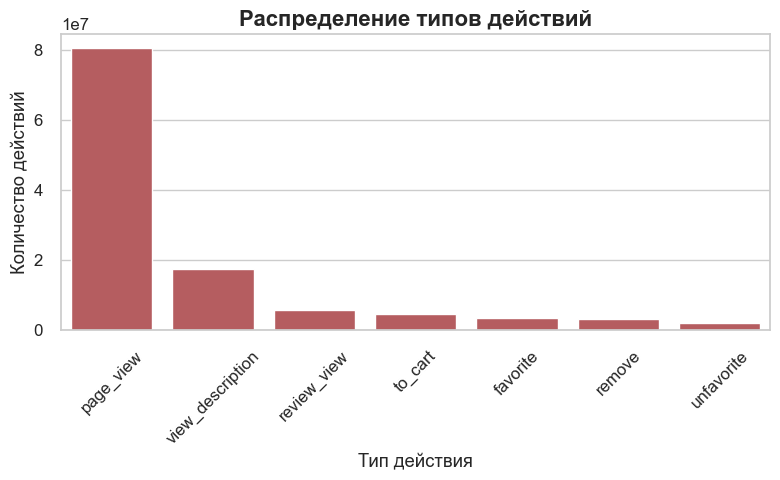

In [42]:
action_counts_new_df = value_counts_col(tracker_new_lf, "action_type")
action_counts_new_df.set_index("action_type", inplace=True)
action_counts_new_df.index.name = None

print("Распределение типов взаимодействий:")
print(action_counts_new_df)

plot_action_types(tracker_new_lf)

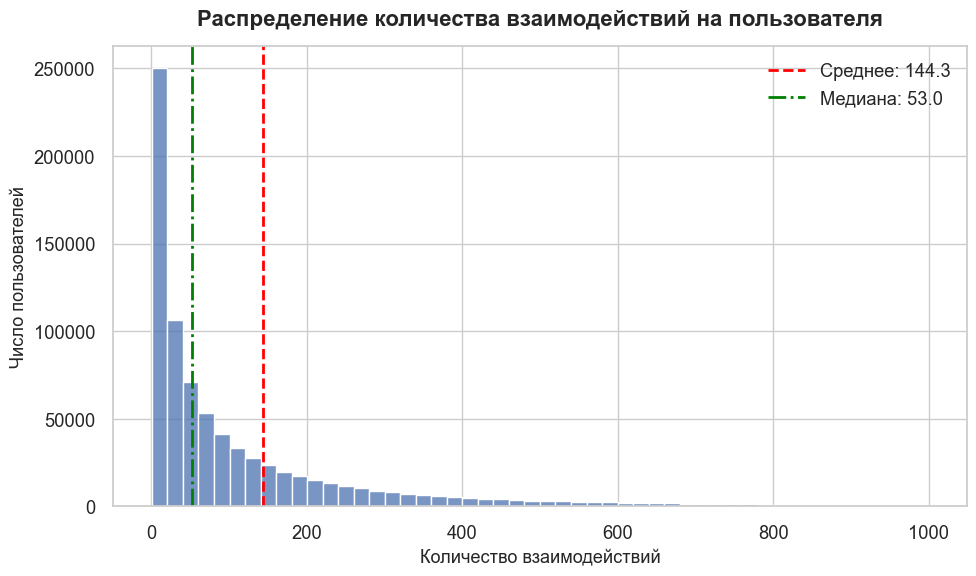

In [43]:
plot_distribution(tracker_new_lf, 1_000, False, 'взаимодействий')

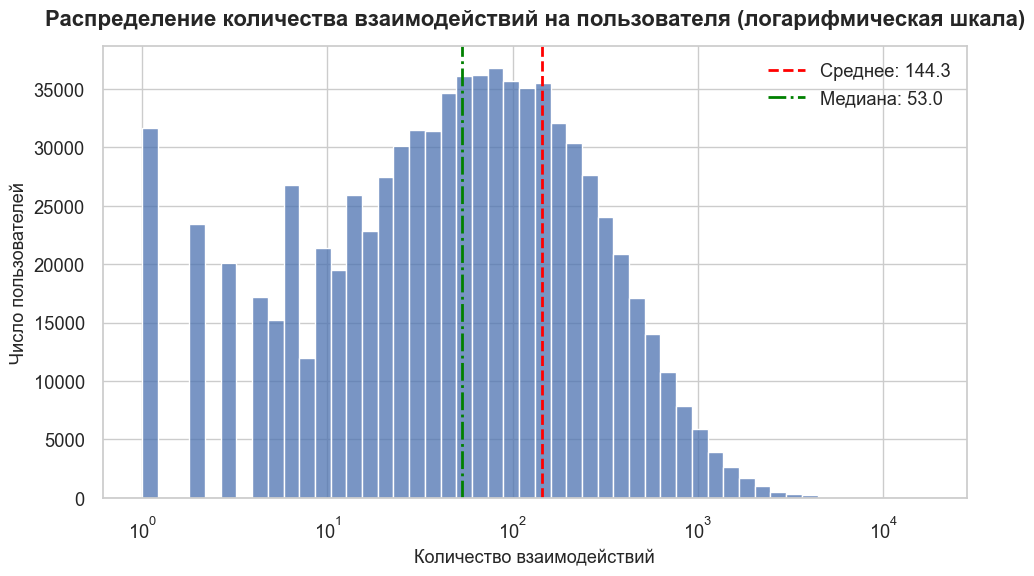

In [44]:
plot_distribution(tracker_new_lf, 1_000_000_000, True, 'взаимодействий')

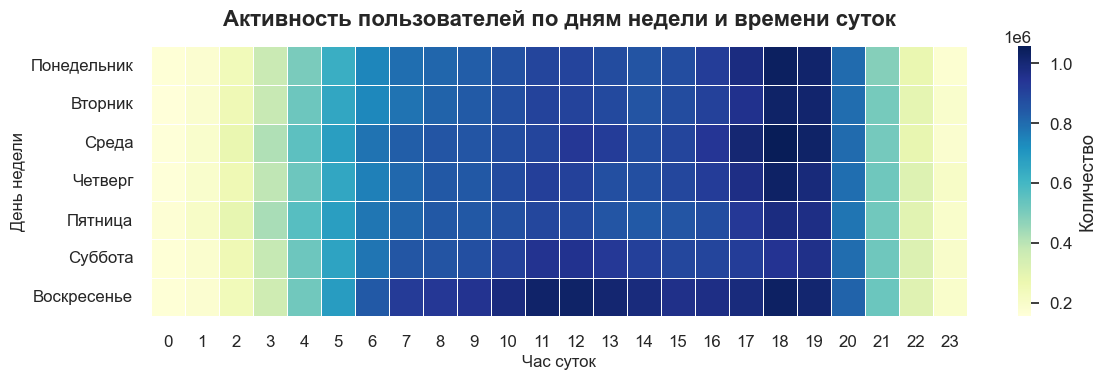

In [45]:
plot_action_per_hours_week_days(tracker_new_lf, "timestamp", "Активность")

In [46]:
print(
    "Количество некорректных timestamp из прошлого: {}".format(
        tracker_new_lf
        .filter(pl.col("timestamp") <= datetime(2025, 7, 1))
        .select(pl.len())
        .collect(engine="streaming")
        .item()
    )
)

(
    tracker_new_lf
    .filter(pl.col("timestamp") <= datetime(2025, 6, 1))
    .head(3)
    .collect(engine="streaming")
)

Количество некорректных timestamp из прошлого: 926


action_widget,item_id,user_id,timestamp,action_type,date
str,i32,i32,datetime[ns],str,date
"""pdp.webCharacteristics""",205234237,3467850,2025-04-11 12:58:54,"""view_description""",2025-07-02
"""shelf.userHistory""",205234237,3467850,2025-04-11 12:58:53,"""page_view""",2025-07-02
"""pdp.webMobRichContent""",122015772,3946580,2025-04-27 08:10:00,"""view_description""",2025-07-02


In [47]:
print(
    "Количество некорректных timestamp из будущего: {}".format(
        tracker_new_lf
        .filter(pl.col("timestamp") >= datetime(2025, 7, 16))
        .select(pl.len())
        .collect(engine="streaming")
        .item()
    )
)

(
    tracker_new_lf
    .filter(pl.col("timestamp") >= datetime(2025, 7, 16))
    .head(3)
    .collect(engine="streaming")
)

Количество некорректных timestamp из будущего: 1181


action_widget,item_id,user_id,timestamp,action_type,date
str,i32,i32,datetime[ns],str,date
"""catalog.searchResultsV2""",174293145,2283521,2025-07-16 09:16:32,"""page_view""",2025-07-12
"""catalog.searchResultsV2""",138665833,2283521,2025-07-16 12:08:47,"""page_view""",2025-07-12
"""catalog.searchResultsV2""",138665833,2283521,2025-07-16 12:05:55,"""page_view""",2025-07-12


### Информация о товарах:
- ml_ozon_recsys_train_final_apparel_items_data

In [48]:
# В каталоге ml_ozon_recsys_train_final_apparel_items_data 100 parquet файлов
items_dir = DATA_DIR / "ml_ozon_recsys_train_final_apparel_items_data"
items_files = list(p.name for p in items_dir.iterdir())
print(len(items_files))
items_files[-5:]

101


['part-00096-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00097-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00098-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00099-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 '_SUCCESS']

In [49]:
items_lf = load_items()
items_lf.head().collect()

item_id,itemname,attributes,fclip_embed,catalogid,variant_id,model_id
i32,str,list[struct[4]],list[f32],i64,i32,i32
400301,"""Очки солнцезащитные""","[{""Type"",""Очки солнцезащитные"",false,true}, {""Brand"",""Нет бренда"",false,true}, … {""ColorBase_Forfilter"",""Розовый"",false,false}]","[0.320239, 0.117663, … 0.038868]",17080,243954236,33306429
678602,"""Футболка GOLDUSTIM Футболка же…","[{""Type"",""Футболка"",false,true}, {""Brand"",""GOLDUSTIM"",false,true}, … {""ColorBase_Forfilter"",""Розовый"",false,false}]","[0.436009, 0.633967, … -0.176413]",7508,8039633,27057398
746401,"""Худи Patagonia""","[{""Type"",""Худи"",false,true}, {""Brand"",""Patagonia"",false,true}, … {""ColorBase_Forfilter"",""Серый"",false,false}]","[0.474528, -0.47278, … 0.553977]",7555,120078071,11645051
872829,"""Комплект носков adidas 3S C Sp…","[{""Type"",""Комплект носков"",false,true}, {""Brand"",""adidas"",false,true}, … {""ColorBase_Forfilter"",""Белый"",false,false}]","[-0.069872, -2.280283, … 0.19949]",36563,247120069,38088455
893255,"""Жилет Buy & Style жилеты""","[{""Type"",""Жилет"",false,true}, {""Brand"",""Buy & Style"",false,true}, … {""ColorBase_Forfilter"",""Черный"",false,false}]","[0.124888, 0.546629, … 0.108914]",7535,327822613,19339929


In [50]:
print("АНАЛИЗ ТОВАРОВ")
print("=" * 40)
items_summary = (
    items_lf.select(
        total_items=pl.len(),
        unique_items=pl.col("item_id").n_unique(),
        items_with_name=pl.col("itemname").is_not_null().sum(),
        items_with_embeddings=pl.col("fclip_embed").is_not_null().sum(),
    )
    .collect(engine="streaming")
    .row(0, named=True)
)

print("Общее количество товаров:      {:,}".format(items_summary["total_items"]))
print("Количество уникальных товаров: {:,}".format(items_summary["unique_items"]))
print("Товары с названием:            {:,}".format(items_summary["items_with_name"]))
print("Товары с эмбеддингами:         {:,}".format(items_summary["items_with_embeddings"]))
print("Количество пропусков:          {:,}".format(null_count_total(items_lf)))

print("\nТоп-10 категорий:")
top_categories = (
    items_lf.group_by("catalogid")
    .len()
    .sort("len", descending=True)
    .head(10)
    .collect(engine="streaming")
    .iter_rows()
)
for cat_id, count in top_categories:
    print(f"  Категория  {cat_id}:\t{count:,}")

АНАЛИЗ ТОВАРОВ
Общее количество товаров:      6,439,422
Количество уникальных товаров: 6,342,024
Товары с названием:            6,439,422
Товары с эмбеддингами:         6,439,422
Количество пропусков:          0

Топ-10 категорий:
  Категория  7559:	413,637
  Категория  7508:	267,444
  Категория  36484:	225,336
  Категория  7660:	219,858
  Категория  7502:	199,919
  Категория  7512:	120,846
  Категория  7511:	108,535
  Категория  7530:	106,773
  Категория  17002:	105,158
  Категория  7644:	101,622


### Каталог (категории) товаров:
- ml_ozon_recsys_train_final_categories_tree

In [51]:
# В каталоге ml_ozon_recsys_train_final_categories_tree 1 parquet файл
categories_dir = DATA_DIR / "ml_ozon_recsys_train_final_categories_tree"
sorted(p.name for p in categories_dir.iterdir())

['_SUCCESS',
 'part-00000-163f9108-23d6-4fd6-98c4-7bcb73ee27e2-c000.snappy.parquet']

In [52]:
categories_lf = load_categories()
categories_lf.head().collect()

catalogid,catalogpath,ids
i64,list[struct[3]],list[i64]
15500,"[{15500,""Электроника"",""Электроника""}, {-1,""Общий каталог"",""Общий каталог""}]","[15500, -1]"
15501,"[{15501,""Телефоны и смарт-часы"",""Телефоны и смарт-часы""}, {15500,""Электроника"",""Электроника""}, {-1,""Общий каталог"",""Общий каталог""}]","[15501, 15500, -1]"
15502,"[{15502,""Смартфоны"",""Смартфоны""}, {15501,""Телефоны и смарт-часы"",""Телефоны и смарт-часы""}, … {-1,""Общий каталог"",""Общий каталог""}]","[15502, 15501, … -1]"
15511,"[{15511,""Аксессуары для смартфонов и телефонов"",""Аксессуары для смартфонов и телефонов""}, {15501,""Телефоны и смарт-часы"",""Телефоны и смарт-часы""}, … {-1,""Общий каталог"",""Общий каталог""}]","[15511, 15501, … -1]"
15892,"[{15892,""Чехлы"",""Чехлы для смартфонов""}, {15511,""Аксессуары для смартфонов и телефонов"",""Аксессуары для смартфонов и телефонов""}, … {-1,""Общий каталог"",""Общий каталог""}]","[15892, 15511, … -1]"


In [53]:
print("АНАЛИЗ КАТАЛОГА ТОВАРОВ")
print("=" * 38)

categories_summary = (
    categories_lf.select(
        total_categories=pl.len(),
        unique_categories=pl.col("catalogid").n_unique(),
    )
    .collect()
    .row(0, named=True)
)

print("Количество категорий:            {:,}".format(categories_summary["total_categories"]))
print("Количество уникальных категорий: {:,}".format(categories_summary["unique_categories"]))
print("Количество пропусков:            {:,}".format(null_count_total(categories_lf)))

АНАЛИЗ КАТАЛОГА ТОВАРОВ
Количество категорий:            7,012
Количество уникальных категорий: 7,012
Количество пропусков:            0


In [54]:
print("Топ-10 категорий по количеству товаров:")

category_names_lf = (
    categories_lf
    .select(
        "catalogid",
        pl.col("catalogpath").list.get(0).struct.field("name").alias("category_name"),
        pl.col("catalogpath").list.get(0).struct.field("fullName").alias("category_full_name"),
    )
)

top_categories = (
    items_lf
    .group_by("catalogid")
    .len()
    .rename({"len": "item_count"})
    .sort("item_count", descending=True)
    .head(10)
    .join(category_names_lf, on="catalogid", how="left", maintain_order="left")
    .collect(engine="streaming")
)

rows = list(top_categories.iter_rows(named=True))

id_width = max(len(str(row["catalogid"])) for row in rows)
name_width = max(len(row["category_name"]) for row in rows)
full_name_width = max(len(row["category_full_name"]) for row in rows)
count_width = max(len(f"{row['item_count']:,}") for row in rows)

for row in rows:
    print(
        f"  {str(row['catalogid']).rjust(id_width)} | "
        f"{row['category_name'].ljust(name_width)} | "
        f"{row['category_full_name'].ljust(full_name_width)} | "
        f"{row['item_count']:>{count_width},}"
    )

Топ-10 категорий по количеству товаров:
   7559 | Футболки и поло           | Футболки и поло мужские           | 413,637
   7508 | Футболки и поло           | Футболки и поло женские           | 267,444
  36484 | Кроссовки и кеды          | Кроссовки и кеды женские          | 225,336
   7660 | Кеды, кроссовки и слипоны | Кеды, кроссовки и слипоны мужские | 219,858
   7502 | Платья и сарафаны         | Платья и сарафаны женские         | 199,919
   7512 | Брюки, бриджи и капри     | Брюки, бриджи и капри женские     | 120,846
   7511 | Блузы и рубашки           | Блузы и рубашки женские           | 108,535
   7530 | Куртки и пуховики         | Куртки и пуховики женские         | 106,773
  17002 | Сумки                     | Сумки женские                     | 105,158
   7644 | Туфли и балетки           | Туфли и балетки женские           | 101,622


### Тестовые данные (id пользователей для рекомендаций)
- ml_ozon_recsys_test.snappy.parquet

In [55]:
test_dir = DATA_DIR / "ml_ozon_recsys_test.snappy.parquet"
test_lf = pl.scan_parquet(test_dir)
test_lf.head(3).collect()

user_id
i32
1857340
4094281
4815130


In [56]:
test_summary = (
    test_lf.select(
        total_rows=pl.len(),
        unique_users=pl.col("user_id").n_unique(),
    )
    .collect()
    .row(0, named=True)
)

print(
    "Датасет содержит:\n"
    "  - {:,} записей\n"
    "  - {:,} уникальных пользователей (user_id)\n".format(
        test_summary["total_rows"],
        test_summary["unique_users"],
    )
)

Датасет содержит:
  - 470,347 записей
  - 470,347 уникальных пользователей (user_id)



## Разделение на обучающую и тестовую выборку

Тестовые данные содержат только user_id и не представляется возможным оценить качество рекомендаций для будущего периода.

Для обучения будет использованны данные о заказах и взаимодействиях с 1 января 2025 по 1 июля 2025

Для оценки будет использованны данные о заказах и взаимодействиях с 2 по 15 июля 2025